# Solar Ray-Tracing with pvlib and PyVista

This notebook performs a simplified solar ray-tracing simulation for the roof surfaces of one selected building. It evaluates shading from nearby buildings and trees throughout the year 2026.

## Objectives

1. **Simplified 3D Scene**: Represent nearby buildings as simple 3D boxes and trees as vertical cones. The target building is excluded from the obstacle mesh to avoid self-intersection.

2. **Target Roof Representation**: Reconstruct the target building's roof facets and sample several points on each roof surface.

3. **Annual Solar Positions**: Calculate solar elevation and azimuth for Würzburg, Germany, at 10-minute intervals during 2026.

4. **Ray-Tracing Simulation**: Cast a ray from every roof sample point towards the Sun at every daylight time step. A point is shaded when the ray intersects a nearby building or tree; otherwise, it is sunlit.

5. **Outputs**: Generate a roof-wise shading time series showing the percentage of sampled points that are shaded on each roof facet at every daylight time step.

In [1]:
import os
import json
import numpy as np
import pandas as pd
import pyvista as pv
import pvlib
from shapely.geometry import Polygon, Point
from earcut import earcut
import time
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


## 1. Configuration and File Paths

This section defines the simulation settings and input file paths.

- **Site location**: Würzburg, Germany  
  Latitude: `49.77243`, Longitude: `9.87073`, Timezone: `Europe/Berlin`

- **Target building ID**: `DEBY_LOD2_506720`

- **Obstacle search radius**: `100 m`  
  Only nearby buildings and trees within this distance from the target building are included as potential shading obstacles.

- **Time series**: 10-minute intervals for the full year 2026.

In [2]:
# Simulation Configuration
LATITUDE = 49.77243
LONGITUDE = 9.87073
TIMEZONE = 'Europe/Berlin'
TARGET_BUILDING_ID = 'DEBY_LOD2_506720'
OBSTACLE_RADIUS_M = 100.0

# Set up paths relative to current directory
if os.path.basename(os.getcwd()) == "notebooks":
    DATA_DIR = "../outputs"
else:
    DATA_DIR = "outputs"

TREES_CSV = os.path.join(DATA_DIR, "wuerzburg_extracted_trees.csv")
ROOFS_CSV = os.path.join(DATA_DIR, "wuerzburg_roof_details.csv")
SURFACES_JSON = os.path.join(DATA_DIR, "cityGML_obj_surfaces.json")
OBJECTS_CSV = os.path.join(DATA_DIR, "cityGML_objects.csv")

print(f"Loading data from: {DATA_DIR}")

Loading data from: ../outputs


## 2. Helper Functions for Geometry and Point Sampling

This section defines helper functions for processing roof geometry and creating roof sample points.

The functions:

- Convert space-separated roof-coordinate strings into 3D NumPy arrays.
- Remove a repeated closing vertex when the first and last roof vertices are identical.
- Fit a plane to the roof vertices to estimate the Z-coordinate of each sampled point.
- Create a centroid point and a regular grid of points inside each roof polygon.
- Remove duplicate sample points.

These roof sample points are later used as ray origins in the shading simulation.

In [3]:
def parse_coords(s: str) -> np.ndarray:
    """Parses a space-separated string of coords into an (N, 3) numpy array."""
    vals = list(map(float, s.split()))
    pts = np.array(vals).reshape(-1, 3)
    if len(pts) > 1 and np.allclose(pts[0], pts[-1]):
        pts = pts[:-1]
    return pts

def sample_grid_points_on_roof(roof_coords_str: str) -> np.ndarray:
    """Samples points on the roof: centroid and a regular grid inside the polygon."""
    v = parse_coords(roof_coords_str)
    
    # 1. Start with the centroid
    sampled = [v.mean(axis=0)]
    
    # 2. Define a bounding box for grid sampling
    min_x, max_x = v[:, 0].min(), v[:, 0].max()
    min_y, max_y = v[:, 1].min(), v[:, 1].max()
    
    # Fit a plane equation: z = a*x + b*y + c using least squares to interpolate Z coords
    A = np.column_stack([v[:, 0], v[:, 1], np.ones(len(v))])
    b = v[:, 2]
    coeff, _, _, _ = np.linalg.lstsq(A, b, rcond=None)
    
    # Create shapely polygon to check if grid points are inside
    poly_2d = Polygon(v[:, :2])
    
    # Generate 5x5 grid coordinates inside the bounding box
    xs = np.linspace(min_x, max_x, 7)[1:-1] # 5 internal steps
    ys = np.linspace(min_y, max_y, 7)[1:-1]
    
    for x_g in xs:
        for y_g in ys:
            if poly_2d.contains(Point(x_g, y_g)):
                # Interpolate height Z
                z_g = coeff[0]*x_g + coeff[1]*y_g + coeff[2]
                sampled.append(np.array([x_g, y_g, z_g]))
                
    # Remove duplicates
    unique_pts = []
    for p in sampled:
        if not any(np.allclose(p, up) for up in unique_pts):
            unique_pts.append(p)
            
    return np.array(unique_pts)

print("Helper functions defined successfully!")

Helper functions defined successfully!


## 3. Data Loading and Spatial Filtering

This section loads the prepared building, roof, and tree datasets.

The target building is identified using its CityGML ID. Its UTM centroid is used as the reference location for the spatial filter.

- Nearby buildings within a 100 m radius are selected as potential shading obstacles.
- Nearby trees within a 100 m radius are selected as potential shading obstacles.
- The target building itself is excluded from the nearby building list to avoid self-intersection during ray tracing.

In this simulation, 48 nearby buildings and 51 nearby trees were selected.

In [4]:
print("Loading datasets...")
df_objects = pd.read_csv(OBJECTS_CSV)
df_trees = pd.read_csv(TREES_CSV)
df_roofs = pd.read_csv(ROOFS_CSV)

# Target building details
target_row = df_objects[df_objects['CityGML_ID'] == TARGET_BUILDING_ID].iloc[0]
cx, cy = target_row['Centroid x UTM'], target_row['Centroid y UTM']
lat = target_row['Centroid Latitude']
lon = target_row['Centroid Longitude']
print(f"Target building centroid: ({cx:.2f}, {cy:.2f})")

# Filter surrounding buildings within 100m, excluding the target building itself
dists_b = np.sqrt((df_objects['Centroid x UTM'] - cx)**2 + (df_objects['Centroid y UTM'] - cy)**2)
nearby_b_ids = df_objects[
    (dists_b <= OBSTACLE_RADIUS_M) & 
    (df_objects['CityGML_ID'] != TARGET_BUILDING_ID)
]['CityGML_ID'].tolist()
print(f"Found {len(nearby_b_ids)} surrounding buildings within {OBSTACLE_RADIUS_M}m.")

# Filter trees within 100m
dists_t = np.sqrt((df_trees['Tree_Position_X'] - cx)**2 + (df_trees['Tree_Position_Y'] - cy)**2)
df_nearby_trees = df_trees[dists_t <= OBSTACLE_RADIUS_M]
print(f"Found {len(df_nearby_trees)} trees within {OBSTACLE_RADIUS_M}m.")

Loading datasets...
Target building centroid: (562696.35, 5513692.88)
Found 48 surrounding buildings within 100.0m.
Found 51 trees within 100.0m.


## 4. Constructing the Simplified 3D Obstacle Scene

This section creates a combined PyVista obstacle mesh for the ray-tracing simulation. The target building is excluded from this mesh to avoid self-intersection.

- Each nearby building is simplified as an axis-aligned 3D bounding box. The box is created from the minimum and maximum X, Y, and Z coordinates of its LoD2 surface geometry.
- Each nearby tree is simplified as a vertical 3D cone. The cone uses the tree position, ground elevation, `cone_height`, and `cone_radius`.
- All building boxes and tree cones are merged into one `obstacle_mesh`.

The final obstacle mesh contains 48 building boxes and 51 tree cones.

In [5]:
print("Loading surfaces JSON...")
with open(SURFACES_JSON, 'r') as f:
    surfaces_data = json.load(f)

# Reconstruct surrounding buildings as simple 3D boxes
building_meshes = []
for b_id in nearby_b_ids:
    if b_id in surfaces_data:
        all_pts = []
        b_data = surfaces_data[b_id]
        for s_type in ['CoordsGroundSurfaces', 'CoordsWallSurfaces', 'CoordsRoofSurfaces']:
            if s_type in b_data:
                for s_str in b_data[s_type]:
                    all_pts.extend(parse_coords(s_str))
        if len(all_pts) == 0:
            continue
        all_pts = np.array(all_pts)
        
        # Build axis-aligned box representing the building
        min_x, max_x = all_pts[:, 0].min(), all_pts[:, 0].max()
        min_y, max_y = all_pts[:, 1].min(), all_pts[:, 1].max()
        min_z, max_z = all_pts[:, 2].min(), all_pts[:, 2].max()
        if max_z == min_z:
            max_z += 5.0  # fallback height
            
        box_mesh = pv.Box(bounds=(min_x, max_x, min_y, max_y, min_z, max_z))
        building_meshes.append(box_mesh)
print(f"Built {len(building_meshes)} building boxes.")

# Reconstruct trees as vertical cones
tree_meshes = []
for idx, row in df_nearby_trees.iterrows():
    h = row['cone_height']
    r = row['cone_radius']
    tx = row['Tree_Position_X']
    ty = row['Tree_Position_Y']
    tz_ground = row['dgmhoehe']
    center = (tx, ty, tz_ground + h / 2.0)
    
    cone = pv.Cone(center=center, direction=(0, 0, 1), height=h, radius=r, resolution=16)
    tree_meshes.append(cone)
print(f"Built {len(tree_meshes)} tree cones.")

# Merge obstacles into a single obstacle mesh for ray-tracing (excluding target building)
obstacle_mesh = pv.merge(building_meshes + tree_meshes)
print("Obstacles merged successfully!")

Loading surfaces JSON...
Built 48 building boxes.
Built 51 tree cones.
Obstacles merged successfully!


## 5. Annual Solar Vector Calculations

This section calculates the Sun position for the target location during the full year 2026.

- A timezone-aware timeline is created at 10-minute intervals from 1 January 2026 to 31 December 2026.
- `pvlib` calculates solar elevation and solar azimuth for every timestamp using the latitude and longitude of the target building.
- A time step is treated as daylight when the solar elevation is greater than `0°`.
- Solar elevation and azimuth are converted into 3D unit vectors that point from the roof towards the Sun.
- Only daylight time steps are passed to the ray-tracing simulation.

The full timeline contains 52,560 time steps. Of these, 26,426 time steps are daylight steps, which is about 50.3% of the yearly timeline.

In [6]:
# Generate timeline for the full year 2026 at 10-minute intervals
timeline = pd.date_range(start='2026-01-01 00:00:00', end='2026-12-31 23:50:00', freq='10min', tz=TIMEZONE)
print(f"Timeline steps: {len(timeline)}")

# Calculate solar position using pvlib
print("Calculating solar positions...")
solar_pos = pvlib.solarposition.get_solarposition(timeline, lat, lon)

df_solar = pd.DataFrame(index=timeline)
df_solar['elevation'] = solar_pos['elevation']
df_solar['azimuth'] = solar_pos['azimuth']
df_solar['is_day'] = df_solar['elevation'] > 0.0

# Convert angles to 3D direction vectors pointing to the Sun
el_rad = np.radians(df_solar['elevation'])
az_rad = np.radians(df_solar['azimuth'])

df_solar['sun_dx'] = np.cos(el_rad) * np.sin(az_rad)
df_solar['sun_dy'] = np.cos(el_rad) * np.cos(az_rad)
df_solar['sun_dz'] = np.sin(el_rad)

sun_vectors = df_solar[['sun_dx', 'sun_dy', 'sun_dz']].values
daytime_indices = np.where(df_solar['is_day'].values)[0]
print(f"Daytime steps: {len(daytime_indices)} ({len(daytime_indices)/len(timeline)*100:.1f}%)")

Timeline steps: 52560
Calculating solar positions...
Daytime steps: 26426 (50.3%)


## 6. Sampling Points on Target Roof

This section creates sample points on the roof surfaces of the target building using the roof geometry stored in `wuerzburg_roof_details.csv`.

For each roof facet:

- The roof vertices are read from the `roof_coords` field.
- A centroid point is created.
- A regular grid of points is generated inside the roof polygon.
- The Z-coordinate of every grid point is calculated from the fitted roof plane.
- Each point receives a roof-specific label, for example `Roof_0_Pt_0`.

The target building has two roof facets. The simulation creates 14 sample points on `Roof_0` and 14 sample points on `Roof_1`, giving 28 roof sample points in total.

In [7]:
target_roofs = df_roofs[df_roofs['Building_ID'] == TARGET_BUILDING_ID]
print(f"Target building {TARGET_BUILDING_ID} has {len(target_roofs)} roof surfaces.")

roof_points = []
roof_labels = []

for _, row in target_roofs.iterrows():
    r_idx = row['Roof_Index']
    coords_str = row['roof_coords']
    pts = sample_grid_points_on_roof(coords_str)
    
    print(f"Roof Index {r_idx}: Sampled {len(pts)} points.")
    for i, pt in enumerate(pts):
        roof_points.append(pt)
        roof_labels.append(f"Roof_{r_idx}_Pt_{i}")

roof_points = np.array(roof_points)
print(f"Total roof sample points: {len(roof_points)}")

Target building DEBY_LOD2_506720 has 2 roof surfaces.
Roof Index 0: Sampled 14 points.
Roof Index 1: Sampled 14 points.
Total roof sample points: 28


## 7. Ray-Tracing Shading Simulation Loop

This section performs the annual shading simulation for all roof sample points during daylight time steps.

For each daylight time step and each roof sample point:

- A 3D Sun-direction vector is selected.
- The ray origin is moved `0.05 m` from the roof point towards the Sun. This small offset avoids self-intersection with the roof.
- A ray is tested from the origin towards the Sun over a distance of `1000 m`.
- The ray is checked against the combined `obstacle_mesh`, which contains nearby building boxes and tree cones.
- If the ray intersects an obstacle, the roof point remains marked as shaded.
- If the ray does not intersect an obstacle, the roof point is marked as sunlit.

The simulation processes 26,426 daylight time steps and 28 roof sample points. This results in 739,928 ray-tracing checks.

The annual simulation completed successfully in approximately 83 seconds.

In [8]:
# Initialize shading matrix (True means shaded, False means sunlit)
# Nighttime steps remain True by default
shading_matrix = np.ones((len(timeline), len(roof_points)), dtype=bool)

total_daytime_steps = len(daytime_indices)
total_roof_points = len(roof_points)
total_rays = total_daytime_steps * total_roof_points

print("Running annual ray-tracing simulation...")
print(f"Daytime steps processed: {total_daytime_steps}")
print(f"Roof sample points: {total_roof_points}")
print(f"Total ray-tracing checks: {total_rays}")

start_time = time.time()

for step_idx in daytime_indices:
    sun_vec = sun_vectors[step_idx]
    
    for pt_idx, pt in enumerate(roof_points):
        # Nudge origin slightly along the sun vector to avoid self-intersection
        origin = pt + sun_vec * 0.05
        end_point = origin + sun_vec * 1000.0
        
        pts, cells = obstacle_mesh.ray_trace(origin, end_point)
        if len(pts) == 0:
            shading_matrix[step_idx, pt_idx] = False
            
runtime_seconds = time.time() - start_time

print("Simulation completed.")
print(f"Runtime: {runtime_seconds:.2f} seconds")

Running annual ray-tracing simulation...
Daytime steps processed: 26426
Roof sample points: 28
Total ray-tracing checks: 739928
Simulation completed.
Runtime: 83.21 seconds


This figure demonstrates one ray-tracing calculation for 19 June 2026 at 12:00 local time. The ray starts 0.05 m above one roof sample point in the direction of the Sun to avoid self-intersection with the roof. It is tested over a length of 1000 m because PyVista requires an origin and endpoint for its line-segment intersection calculation. The displayed red ray is shortened to 150 m only to keep the plot readable.


Example ray-tracing result
Timestamp: 2026-06-19 12:00:00+02:00
Roof point: Roof_0_Pt_0
Solar elevation: 59.17°
Solar azimuth: 141.23°
Result: Sunlit — no obstacle intersection was found.


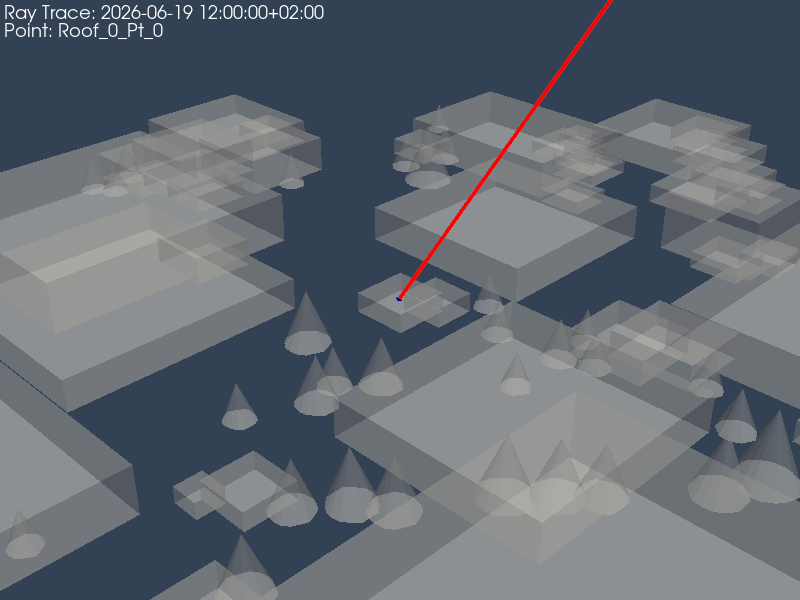

In [9]:
# ------------------ EXAMPLE RAY-TRACING PLOT ------------------
EXAMPLE_TIME = pd.Timestamp(
    '2026-06-19 12:00:00',
    tz=TIMEZONE
)
example_step_idx = timeline.get_indexer(
    [EXAMPLE_TIME],
    method='nearest'
)[0]
example_timestamp = timeline[example_step_idx]
example_pt_idx = 0
example_pt = roof_points[example_pt_idx]
example_label = roof_labels[example_pt_idx]
example_sun_vec = sun_vectors[example_step_idx]

ORIGIN_OFFSET_M = 0.05
RAY_LENGTH_M = 1000.0

example_origin = example_pt + example_sun_vec * ORIGIN_OFFSET_M
example_end_point = example_origin + example_sun_vec * RAY_LENGTH_M

intersection_points, intersection_cells = obstacle_mesh.ray_trace(
    example_origin,
    example_end_point
)

print("\nExample ray-tracing result")
print(f"Timestamp: {example_timestamp}")
print(f"Roof point: {example_label}")
print(f"Solar elevation: {df_solar.iloc[example_step_idx]['elevation']:.2f}°")
print(f"Solar azimuth: {df_solar.iloc[example_step_idx]['azimuth']:.2f}°")
if len(intersection_points) > 0:
    print("Result: Shaded — the ray intersects an obstacle.")
else:
    print("Result: Sunlit — no obstacle intersection was found.")

# PyVista Plotting
DISPLAY_RAY_LENGTH_M = 150.0
display_end_point = example_origin + example_sun_vec * DISPLAY_RAY_LENGTH_M
display_ray_line = pv.Line(example_origin, display_end_point)

plotter = pv.Plotter(off_screen=True, window_size=(800, 600))
plotter.add_mesh(obstacle_mesh, color='#d1d5db', opacity=0.45, label='Obstacles')

origin_sphere = pv.Sphere(radius=0.3, center=example_origin)
plotter.add_mesh(origin_sphere, color='blue', label='Ray Origin')

plotter.add_mesh(display_ray_line, color='red', line_width=4, label='Solar Ray (150m)')

if len(intersection_points) > 0:
    for pt in intersection_points:
        isect_sphere = pv.Sphere(radius=0.4, center=pt)
        plotter.add_mesh(isect_sphere, color='black')

plotter.add_text(f"Ray Trace: {example_timestamp}\nPoint: {example_label}", position='upper_left', font_size=10, color='white')
plotter.set_background('#334155')
plotter.camera_position = [
    (example_origin[0] - 100, example_origin[1] - 100, example_origin[2] + 80),
    (example_origin[0], example_origin[1], example_origin[2]),
    (0, 0, 1)
]
plotter.show(jupyter_backend='static')


## 8. Roof-Wise Shading Time Series

For every daylight time step, the shading state of all sample points on the same roof facet is averaged.

- `0%` means all sampled points on the roof are sunlit.
- `100%` means all sampled points on the roof are shaded.
- Intermediate values show partial roof shading.

In [10]:
# ------------------ ROOF-WISE SHADING TIME SERIES ------------------
roof_ids = np.array([
    label.split('_Pt_')[0]
    for label in roof_labels
])

time_series_rows = []

for step_idx in daytime_indices:
    timestamp = timeline[step_idx]

    for roof_id in np.unique(roof_ids):
        roof_point_indices = np.where(roof_ids == roof_id)[0]

        shading_percent = (
            shading_matrix[step_idx, roof_point_indices].mean() * 100.0
        )

        time_series_rows.append({
            'timestamp': timestamp,
            'roof_id': roof_id,
            'shading_percent': round(shading_percent, 2)
        })

df_roof_timeseries = pd.DataFrame(time_series_rows)

print("Roof-wise shading time series (daylight time steps only):")
display(df_roof_timeseries.head(20))

Roof-wise shading time series (daylight time steps only):


,timestamp,roof_id,shading_percent
0,2026-01-01 08:30:00+01:00,Roof_0,71.43
1,2026-01-01 08:30:00+01:00,Roof_1,78.57
2,2026-01-01 08:40:00+01:00,Roof_0,28.57
3,2026-01-01 08:40:00+01:00,Roof_1,35.71
4,2026-01-01 08:50:00+01:00,Roof_0,0.00
5,2026-01-01 08:50:00+01:00,Roof_1,7.14
6,2026-01-01 09:00:00+01:00,Roof_0,0.00
7,2026-01-01 09:00:00+01:00,Roof_1,0.00
8,2026-01-01 09:10:00+01:00,Roof_0,0.00
9,2026-01-01 09:10:00+01:00,Roof_1,0.00
